# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** Colab T4, датасет - [tner/bc5cdr](https://huggingface.co/datasets/tner/bc5cdr) (лицензия в карточке TNER: `other`), основная модель - [BioBERT](https://huggingface.co/dmis-lab/biobert-base-cased-v1.2) (лицензия в метаданных Hub не указана), для сравнения - [BERT-base-cased](https://huggingface.co/google-bert/bert-base-cased) (Apache-2.0). В работе я опиралась на материалы задания, документацию Hugging Face и карточки этих ресурсов.

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path
from IPython.display import Markdown, display

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.14.1+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)


def show_answer(markdown_text):
    display(Markdown('**Ответ:** ' + markdown_text))

cuda Tesla T4


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.1', '6.2', '6.3', '6.4', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}
SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None   # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128   # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}
BONUS_RESULTS = {}
RUN_HEAD_LR_DIAGNOSTIC = True

manual_file = ARTIFACTS / 'manual_annotations.jsonl'
if '6.1' in BONUS_TASKS and not manual_file.exists():
    try:
        from google.colab import files as colab_files
    except ImportError as exc:
        raise FileNotFoundError(f'Загрузите {manual_file} перед запуском бонуса 6.1') from exc
    print('Выберите manual_annotations.jsonl для бонуса 6.1:')
    uploaded = colab_files.upload()
    if manual_file.name not in uploaded:
        raise FileNotFoundError(f'Нужен файл {manual_file.name}; эксперимент 6.1 не должен незаметно пропускаться')
    manual_file.write_bytes(uploaded[manual_file.name])
    print('Загружен', manual_file, manual_file.stat().st_size, 'bytes')

Выберите manual_annotations.jsonl для бонуса 6.1:


Saving manual_annotations.jsonl to manual_annotations.jsonl
Загружен artifacts/manual_annotations.jsonl 21728 bytes


---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'dmis-lab/biobert-base-cased-v1.2'
REVISION = '67c9c25b46986521ca33df05d8540da1210b3256'
TOKENIZER_KWARGS = {'use_fast': True, 'do_lower_case': False}   # для roberta-base: {'add_prefix_space': True}
COMPARISON_MODEL_ID = 'google-bert/bert-base-cased'
COMPARISON_REVISION = 'cd5ef92a9fb2f889e972770a36d4ed042daf221e'

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
assert tokenizer.do_lower_case is False, 'Для cased BioBERT надо задать do_lower_case=False'
case_samples = ['Naloxone CO NH3 RA', 'naloxone co nh3 ra']
case_ids = [tokenizer(text)['input_ids'] for text in case_samples]
assert case_ids[0] != case_ids[1], 'Регистр не должен исчезать в cased-токенизаторе'
print('do_lower_case:', tokenizer.do_lower_case)
print('case-sensitive tokens:', tokenizer.tokenize(case_samples[0]))
print('lowercase tokens:', tokenizer.tokenize(case_samples[1]))
print('Cyrillic diagnostic:', tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    dmis-lab/biobert-base-cased-v1.2
revision: 67c9c25b46986521ca33df05d8540da1210b3256
license:  None
language: None
updated:  2021-06-24 02:54:58+00:00
weights:  {'pytorch_model.bin': '416 MB'}


config.json:   0%|          | 0.00/1.11k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

BertTokenizer vocab size 28996
do_lower_case: False
case-sensitive tokens: ['Na', '##lo', '##xon', '##e', 'CO', 'NH', '##3', 'RA']
lowercase tokens: ['na', '##lo', '##xon', '##e', 'co', 'n', '##h', '##3', 'r', '##a']
Cyrillic diagnostic: ['П', '##е', '##т', '##р', 'И', '##л', '##ь', '##и', '##ч', 'Ч', '##а', '##й', '##к', '##ов', '##с', '##к', '##ий', 'р', '##о', '##д', '##и', '##л', '##с', '##я', 'в', 'В', '##о', '##т', '##к', '##и', '##н', '##с', '##к', '##е']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** Я выбрала англоязычную BioBERT, дополнительно предобученную на биомедицинских текстах: для Chemical/Disease NER это подходящее доменное представление, а размер около 107,7 млн параметров позволяет обучать модель на T4 за минуты. В моём эксперименте обычная bert-base-cased при примерно том же размере и времени обучения получила 85,01% Test F1 против 88,14% у BioBERT; более компактные модели могли бы работать быстрее, но их качество я не проверяла. В карточке весов BioBERT лицензия не указана, хотя код проекта опубликован под Apache-2.0. Я зафиксировала полный revision, чтобы будущие изменения весов, токенизатора или конфигурации на Hub не нарушили воспроизводимость.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 28996, 'hidden_size': 768, 'num_hidden_layers': 12, 'num_attention_heads': 12, 'intermediate_size': 3072, 'max_position_embeddings': 512}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    base = model.base_model
    layers = base.encoder.layer
    ids_embeddings = {id(p) for p in base.embeddings.parameters()}
    ids_layers = [{id(p) for p in layer.parameters()} for layer in layers]
    ids_encoder = set().union(*ids_layers)
    ids_head = {id(p) for p in model.classifier.parameters()}
    groups = [ids_embeddings, ids_encoder, ids_head]
    assert not any(groups[i] & groups[j] for i in range(3) for j in range(i))
    sizes = {id(p): p.numel() for p in model.parameters()}
    result = {key: sum(sizes[i] for i in group) for key, group in
              zip(['embeddings', 'encoder', 'head'], groups)}
    result['other'] = sum(v for i, v in sizes.items() if i not in set().union(*groups))
    result['layers'] = [sum(sizes[i] for i in group) for group in ids_layers]
    return result

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    22,665,216   21.0%
encoder       85,054,464   79.0%
head               5,383    0.0%
other                  0    0.0%
total        107,725,063
per layer: [7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872]


In [10]:
demo_texts = [['Aspirin', 'may', 'cause', 'gastric', 'bleeding', '.'],
              ['Chemical', 'exposure', 'was', 'associated', 'with', 'disease', '.']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)
print('input_ids', tuple(enc['input_ids'].shape))
print('embeddings', tuple(out.hidden_states[0].shape))
print('encoder layers', [tuple(h.shape) for h in out.hidden_states[1:]])
print('logits', tuple(out.logits.shape))

input_ids (2, 11)
embeddings (2, 11, 768)
encoder layers [(2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768)]
logits (2, 11, 7)


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 250: 375.6 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** input_ids размера (2, 11): после эмбеддингов и каждого из 12 слоёв энкодера форма равна (2, 11, 768), а голова выдаёт logits (2, 11, 7). Больше всего параметров оказалось в энкодере — 85,05 млн, или около 79% всех параметров, поскольку в слоях находятся матрицы attention и FFN. Между токенами информация передаётся в энкодере, тогда как линейная классификационная голова обрабатывает представление каждого токена отдельно. Длина T = 11 больше числа исходных слов из-за разбиения слов на сабворды и добавления специальных токенов.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)


In [13]:
DATASET_ID, DATASET_CONFIG = 'tner/bc5cdr', None
DATASET_REVISION = '564118257f090b2592b7b1607ec60f40948acf1c'
raw = load_dataset(DATASET_ID, revision=DATASET_REVISION)
raw = DatasetDict({split: ds.rename_column('tags', 'ner_tags') for split, ds in raw.items()})
LABEL_NAMES = ['O', 'B-Chemical', 'B-Disease', 'I-Disease', 'I-Chemical']
for split, ds in raw.items():
    assert len(ds) > 0
    for ex in ds:
        assert len(ex['tokens']) == len(ex['ner_tags'])
        assert all(isinstance(w, str) and w for w in ex['tokens'])
        assert all(0 <= t < len(LABEL_NAMES) for t in ex['ner_tags'])
print(raw)
print(list(zip(raw['train'][0]['tokens'], [LABEL_NAMES[t] for t in raw['train'][0]['ner_tags']])))

0000.parquet:   0%|          | 0.00/367k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/364k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/386k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 5228
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 5330
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 5865
    })
})
[('Naloxone', 'B-Chemical'), ('reverses', 'O'), ('the', 'O'), ('antihypertensive', 'O'), ('effect', 'O'), ('of', 'O'), ('clonidine', 'B-Chemical'), ('.', 'O')]


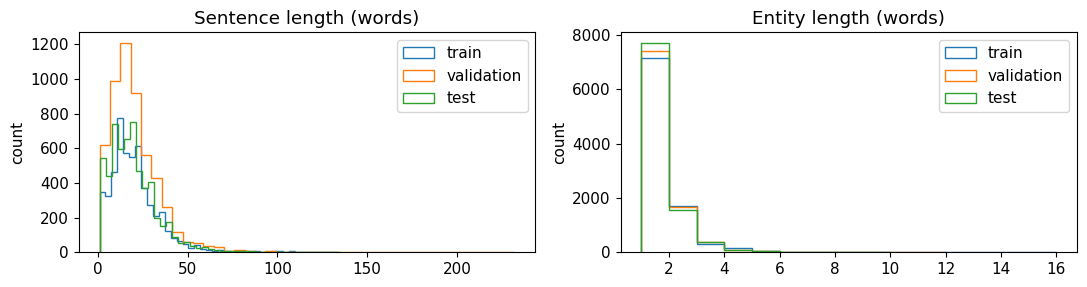

{
  "train": {
    "sentences": 5228,
    "entities": {
      "Chemical": 5203,
      "Disease": 4182
    },
    "span_lengths": {
      "n": 9385,
      "mean": 1.3346830047948854,
      "median": 1.0,
      "p95": 3.0,
      "maximum": 15
    },
    "sentence_lengths": {
      "n": 5228,
      "mean": 20.910864575363426,
      "median": 18.0,
      "p95": 46.0,
      "maximum": 133
    }
  },
  "validation": {
    "sentences": 5330,
    "entities": {
      "Disease": 4244,
      "Chemical": 5347
    },
    "span_lengths": {
      "n": 9591,
      "mean": 1.3079970805963925,
      "median": 1.0,
      "p95": 3.0,
      "maximum": 11
    },
    "sentence_lengths": {
      "n": 5330,
      "mean": 20.442401500938086,
      "median": 18.0,
      "p95": 45.0,
      "maximum": 232
    }
  },
  "test": {
    "sentences": 5865,
    "entities": {
      "Chemical": 5385,
      "Disease": 4424
    },
    "span_lengths": {
      "n": 9809,
      "mean": 1.2880008155775309,
      "median": 1.0,
 

In [14]:
# ваша статистика: сущности по типам и сплитам, длины спанов в словах, длины предложений
def describe_lengths(values):
    return dict(n=len(values), mean=float(np.mean(values)) if values else 0.,
                median=float(np.median(values)) if values else 0.,
                p95=float(np.percentile(values, 95)) if values else 0.,
                maximum=max(values, default=0))

dataset_stats = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for split, ds in raw.items():
    counts, lengths, sentences = collections.Counter(), [], []
    for ex in ds:
        tags = [LABEL_NAMES[t] for t in ex['ner_tags']]
        sentences.append(len(tags))
        active, size = None, 0
        for tag in tags + ['O']:
            typ = tag[2:] if tag != 'O' else None
            if active is not None and (tag.startswith('B-') or typ != active):
                counts[active] += 1
                lengths.append(size)
                active, size = None, 0
            if typ is not None:
                active, size = typ, size + 1
    dataset_stats[split] = dict(sentences=len(ds), entities=dict(counts),
                               span_lengths=describe_lengths(lengths),
                               sentence_lengths=describe_lengths(sentences))
    axes[0].hist(sentences, bins=40, histtype='step', label=split)
    axes[1].hist(lengths, bins=range(1, max(lengths) + 2), histtype='step', label=split)
for ax, title in zip(axes, ['Sentence length (words)', 'Entity length (words)']):
    ax.set_title(title)
    ax.set_ylabel('count')
    ax.legend()
plt.tight_layout()
plt.savefig(ARTIFACTS / 'data_lengths.png')
plt.show()
print(json.dumps(dataset_stats, ensure_ascii=False, indent=2))

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** Я использовала англоязычный BC5CDR из T-NER, основанный на экспертной разметке биомедицинских текстов; лицензия этой версии датасета в карточке указана как other. Выборки train/validation/test содержат 5228/5330/5865 предложений, 5203/5347/5385 сущностей Chemical и 4182/4244/4424 сущностей Disease. Средняя длина спана в train — 1,33 слова, 95% спанов имеют длину не более 3 слов, средняя длина предложения — 20,9 слова. Повторяющиеся короткие названия упрощают распознавание, а многословные формулировки и неоднозначные границы усложняют задачу.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans, start, active = [], None, None
    for i, tag in enumerate(list(tags) + ['O']):
        if tag != 'O' and not re.fullmatch(r'[BI]-.+', tag):
            raise ValueError(f'Invalid BIO tag: {tag}')
        typ = tag[2:] if tag != 'O' else None
        if active is not None and (tag.startswith('B-') or typ != active):
            spans.append((start, i, active))
            start, active = None, None
        if typ is not None and active is None:
            start, active = i, typ
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    if not isinstance(n_words, int) or n_words < 0:
        raise ValueError('n_words must be a nonnegative integer')
    tags = ['O'] * n_words
    for start, end, typ in sorted(spans):
        if not (isinstance(start, int) and isinstance(end, int) and 0 <= start < end <= n_words):
            raise ValueError(f'Invalid span: {(start, end, typ)}')
        if not isinstance(typ, str) or not typ or any(t != 'O' for t in tags[start:end]):
            raise ValueError('Empty type or overlapping spans')
        tags[start:end] = ['B-' + typ] + ['I-' + typ] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    aligned, seen = [], set()
    for w in word_ids:
        if w is None:
            aligned.append(-100)
        elif w not in seen:
            aligned.append(word_labels[w])
            seen.add(w)
        elif b_to_i is None:
            aligned.append(-100)
        else:
            aligned.append(b_to_i.get(word_labels[w], word_labels[w]))
    return aligned

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]   # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]   # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
# если датасет не в формате «слова + BIO»: конвертация в контракт из 2.1
# если уже в BIO: экспорт в спаны JSON (data/<split>_spans.jsonl), чтение обратно, BIO, сравнение с исходным
Path('data').mkdir(exist_ok=True)
roundtrip_stats = {}
for split, ds in raw.items():
    path = Path('data') / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as f:
        for ex in ds:
            tags = [LABEL_NAMES[t] for t in ex['ner_tags']]
            f.write(json.dumps(dict(tokens=ex['tokens'], spans=bio_to_spans(tags)), ensure_ascii=False) + '\n')
    changed, checked = 0, 0
    with path.open(encoding='utf-8') as f:
        for ex, line in zip(ds, f):
            obj = json.loads(line)
            spans = [tuple(s) for s in obj['spans']]
            tags = [LABEL_NAMES[t] for t in ex['ner_tags']]
            back = spans_to_bio(spans, len(obj['tokens']))
            assert obj['tokens'] == ex['tokens'] and bio_to_spans(back) == bio_to_spans(tags)
            changed += back != tags
            checked += 1
    assert checked == len(ds)
    roundtrip_stats[split] = dict(checked=checked, noncanonical_bio=changed)
    print(split, roundtrip_stats[split])
print('Example:', json.loads(Path('data/train_spans.jsonl').read_text(encoding='utf-8').splitlines()[0]))

train {'checked': 5228, 'noncanonical_bio': 0}
validation {'checked': 5330, 'noncanonical_bio': 0}
test {'checked': 5865, 'noncanonical_bio': 0}
Example: {'tokens': ['Naloxone', 'reverses', 'the', 'antihypertensive', 'effect', 'of', 'clonidine', '.'], 'spans': [[0, 1, 'Chemical'], [6, 7, 'Chemical']]}


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
truncation_stats = {}
for split_name, split_ds in data.items():
    truncated_sentences = lost_words = affected_gold_entities = checked = 0
    for example in split_ds:
        enc = tokenizer(example['tokens'], is_split_into_words=True,
                        truncation=True, max_length=MAX_LENGTH)
        full_enc = tokenizer(example['tokens'], is_split_into_words=True, truncation=False)
        word_ids = enc.word_ids()
        aligned = align_labels(example['ner_tags'], word_ids)
        got = {w: label for w, label in zip(word_ids, aligned) if label != -100}
        observed = set(got)
        original_word_counts = collections.Counter(w for w in full_enc.word_ids() if w is not None)
        observed_word_counts = collections.Counter(w for w in word_ids if w is not None)
        fully_visible = {w for w, count in original_word_counts.items()
                         if observed_word_counts[w] == count}
        assert got == {w: example['ner_tags'][w] for w in set(word_ids) - {None}}
        truncated_sentences += int(len(full_enc['input_ids']) > MAX_LENGTH)
        lost_words += len(example['tokens']) - len(observed)
        gold_spans = bio_to_spans([LABEL_NAMES[t] for t in example['ner_tags']])
        affected_gold_entities += sum(any(w not in fully_visible for w in range(a, b))
                                      for a, b, _ in gold_spans)
        if len(observed) == len(example['tokens']):
            recovered = [LABEL_NAMES[got[w]] for w in range(len(example['tokens']))]
            assert bio_to_spans(recovered) == gold_spans
            checked += 1
    truncation_stats[split_name] = dict(sentences=len(split_ds),
                                        truncated_sentences=truncated_sentences,
                                        words_without_label=lost_words,
                                        gold_entities_affected=affected_gold_entities,
                                        full_alignment_checked=checked)
    print(split_name, truncation_stats[split_name])

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/5228 [00:00<?, ? examples/s]

Map:   0%|          | 0/5330 [00:00<?, ? examples/s]

Map:   0%|          | 0/5865 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 5228
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 5330
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 5865
    })
})
ENTITY_TYPES ['Chemical', 'Disease']
train {'sentences': 5228, 'truncated_sentences': 38, 'words_without_label': 559, 'gold_entities_affected': 41, 'full_alignment_checked': 5190}
validation {'sentences': 5330, 'truncated_sentences': 21, 'words_without_label': 586, 'gold_entities_affected': 47, 'full_alignment_checked': 5309}
test {'sentences': 5865, 'truncated_sentences': 20, 'words_without_label': 343, 'gold_entities_affected': 28, 'full_alignment_checked': 5845}
[CLS]            None  -100
Na                  0  B-Chemical
##lo                0  -100
##xon               0  -100
##e                 0  -100
reverse             1  O
##s                 1  -100
the                 2  O
anti  

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Я назначала BIO-метку только первому сабворду каждого слова, а специальным токенам и остальным сабвордам — -100, чтобы они не учитывались в loss. При MAX_LENGTH = 128 обрезались 38/21/20 предложений в train/validation/test, и 559/586/343 слова соответственно остались без меток; это могло затронуть некоторые истинные сущности. Проверка BIO → спаны → BIO прошла для всех 5228/5330/5865 предложений без неканонических последовательностей. В используемой BIO-разметке нет вложенных или пересекающихся сущностей, а соответствие слов и сабвордов я обрабатывала через word_ids().

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    assert len(tokens_list) == len(tags_list)
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        assert len(words) == len(tags)
        for word, tag in zip(words, tags):
            counts[word][tag] += 1
    return {w: min(c, key=lambda t: (-c[t], t)) for w, c in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(w, 'O') for w in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_gold = [[LABEL_NAMES[t] for t in tags] for tags in data['train']['ner_tags']]
majority_tagger = fit_majority_tagger(data['train']['tokens'], train_gold)
majority_pred = [predict_majority(majority_tagger, ws) for ws in val_tokens]
set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline = dict(majority=entity_scores(val_gold, majority_pred),
                random_head=entity_scores(val_gold, random_pred))
del random_model
for name in ['demo_model', 'out', 'x']:
    globals().pop(name, None)
import gc
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print(json.dumps(baseline, indent=2))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{
  "majority": {
    "f1_micro": 0.625501560410165,
    "f1_macro": 0.6244351566240045,
    "precision": 0.6718544235603975,
    "recall": 0.5851318944844125
  },
  "random_head": {
    "f1_micro": 0.06947598253275108,
    "f1_macro": 0.07043170114846399,
    "precision": 0.043939352094783064,
    "recall": 0.16588468355750183
  }
}


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** На validation словарный Majority Tagger получил Entity F1 = 62,55%: он использует повторяющиеся названия сущностей, но не учитывает контекст и плохо переносится на незнакомые слова. Энкодер со случайной классификационной головой дал только 6,95%, поскольку голова ещё не обучена распознавать BIO-метки. После полноценного дообучения BioBERT достигла 88,76% на validation.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 3e-5   # подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 16   # уменьшите, если не влезает в память T4


def eval_entity_f1(eval_prediction):
    logits = eval_prediction.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    predicted_ids = np.argmax(logits, axis=-1)
    labels = eval_prediction.label_ids
    gold_sequences, predicted_sequences = [], []
    for prediction, label in zip(predicted_ids, labels):
        valid = label != -100
        gold_sequences.append([LABEL_NAMES[int(v)] for v in label[valid]])
        predicted_sequences.append([LABEL_NAMES[int(v)] for v in prediction[valid]])
    return {'f1': float(f1_score(gold_sequences, predicted_sequences,
                                 average='micro', zero_division=0))}


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    for p in model.parameters():
        p.requires_grad_(True)
    if freeze_encoder:
        for p in model.base_model.parameters():
            p.requires_grad_(False)
    steps = math.ceil(len(train_ds) / batch_size) * epochs
    interval = max(1, int(steps // 12))
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=batch_size * 2,
        eval_strategy='steps', eval_steps=interval, logging_strategy='steps', logging_steps=interval,
        logging_first_step=True, save_strategy='no', report_to='none',
        warmup_steps=0.1, weight_decay=0.01, lr_scheduler_type='linear',
        fp16=device.type == 'cuda', bf16=False, seed=SEED, data_seed=SEED,
        dataloader_num_workers=0, dataloader_pin_memory=device.type == 'cuda',
        optim='adamw_torch', max_grad_norm=1.0)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      processing_class=tok, compute_metrics=eval_entity_f1,
                      data_collator=DataCollatorForTokenClassification(tok, pad_to_multiple_of=8))
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    trainer.train()
    trainer.evaluate()
    if device.type == 'cuda':
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    history = copy.deepcopy(trainer.state.log_history)
    del trainer
    return history, seconds

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.862', 'grad_norm': 'inf', 'learning_rate': '0', 'epoch': '0.003058'}
{'loss': '0.738', 'grad_norm': '0.8904', 'learning_rate': '2.333e-05', 'epoch': '0.2477'}
{'eval_loss': '0.1237', 'eval_f1': '0.7641', 'eval_runtime': '7.059', 'eval_samples_per_second': '755.1', 'eval_steps_per_second': '23.66', 'epoch': '0.2477'}
{'loss': '0.1012', 'grad_norm': '1.596', 'learning_rate': '2.799e-05', 'epoch': '0.4954'}
{'eval_loss': '0.08238', 'eval_f1': '0.8715', 'eval_runtime': '7.221', 'eval_samples_per_second': '738.1', 'eval_steps_per_second': '23.12', 'epoch': '0.4954'}
{'loss': '0.08122', 'grad_norm': '1.709', 'learning_rate': '2.524e-05', 'epoch': '0.7431'}
{'eval_loss': '0.07835', 'eval_f1': '0.8773', 'eval_runtime': '7.275', 'eval_samples_per_second': '732.7', 'eval_steps_per_second': '22.96', 'epoch': '0.7431'}
{'loss': '0.06907', 'grad_norm': '1.1', 'learning_rate': '2.248e-05', 'epoch': '0.9908'}
{'eval_loss': '0.06941', 'eval_f1': '0.8809', 'eval_runtime': '7.631', 'eval_sam

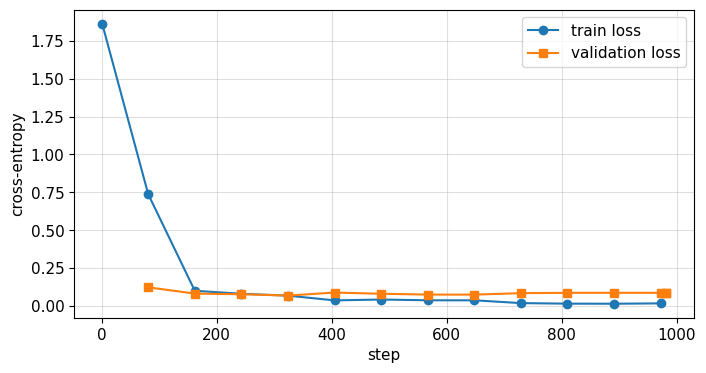

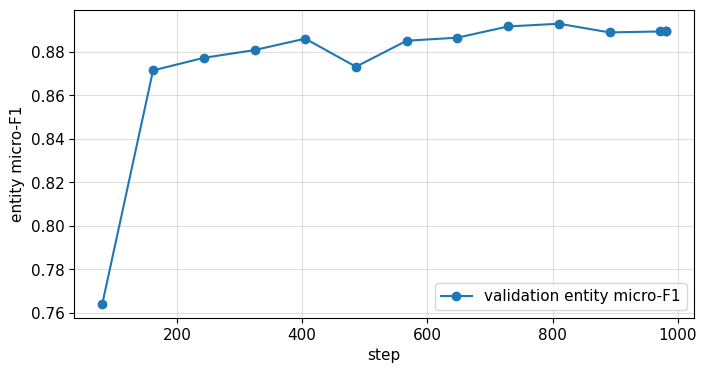

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

f1_curve = [(entry['step'], entry['eval_f1']) for entry in history if 'eval_f1' in entry]
assert len(f1_curve) >= 2, 'Нужны значения validation entity-F1 во время обучения'
plt.figure(figsize=(8, 4))
plt.plot(*zip(*f1_curve), 'o-', label='validation entity micro-F1')
plt.xlabel('step')
plt.ylabel('entity micro-F1')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()


**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** Я выбрала learning rate = 3e-5, batch size = 16, три эпохи, линейный scheduler с 10% warmup, weight_decay = 0.01 и mixed precision на GPU. Train loss последовательно снижался, но к концу обучения validation loss начал ухудшаться, поэтому увеличение числа эпох без проверки могло бы усилить переобучение. Обучение основной модели на Tesla T4 заняло 218,6 секунды (около 3,64 минуты).

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    assert len(gold) == len(pred)
    tp = n_gold = n_pred = 0
    for gs, ps in zip(gold, pred):
        assert len(gs) == len(ps)
        for g, p in zip(gs, ps):
            n_gold += g != 'O'
            n_pred += p != 'O'
            tp += g == p and g != 'O'
    return 2 * tp / (n_gold + n_pred) if n_gold + n_pred else 0.0


def full_scores(gold, pred):
    has_entities = any(bio_to_spans(s) for s in gold) or any(bio_to_spans(s) for s in pred)
    report = classification_report(gold, pred, output_dict=True, zero_division=0) if has_entities else {}
    scores = entity_scores(gold, pred) if has_entities else dict(f1_micro=0., f1_macro=0., precision=0., recall=0.)
    return dict(**scores, token_f1=token_f1(gold, pred),
                per_type={t: report.get(t, {'precision': 0., 'recall': 0., 'f1-score': 0., 'support': 0})
                          for t in ENTITY_TYPES})

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9   # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9   # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

val_pred = predict_word_tags(model, val_tokens)   # предсказанные теги validation (список списков), нужны в 5.1
validation_metrics = full_scores(val_gold, val_pred)
test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
test_pred = predict_word_tags(model, test_tokens)
final = full_scores(test_gold, test_pred)
for split, gold, pred in [('validation', val_gold, val_pred), ('test', test_gold, test_pred)]:
    print(split)
    print(classification_report(gold, pred, digits=4, zero_division=0))
    print(full_scores(gold, pred))
    print('token F1 / entity F1:', token_f1(gold, pred), f1_score(gold, pred, zero_division=0))

validation
              precision    recall  f1-score   support

    Chemical     0.9365    0.9373    0.9369      5347
     Disease     0.8036    0.8525    0.8273      4244

   micro avg     0.8758    0.8998    0.8876      9591
   macro avg     0.8701    0.8949    0.8821      9591
weighted avg     0.8777    0.8998    0.8884      9591

{'f1_micro': np.float64(0.8876317819490872), 'f1_macro': np.float64(0.8821298185701256), 'precision': np.float64(0.8757864826466409), 'recall': np.float64(0.8998018976123449), 'token_f1': 0.8838197121057185, 'per_type': {'Chemical': {'precision': np.float64(0.9364723467862481), 'recall': np.float64(0.9373480456330653), 'f1-score': np.float64(0.9369099915879989), 'support': np.int64(5347)}, 'Disease': {'precision': np.float64(0.8036428254109285), 'recall': np.float64(0.852497643732328), 'f1-score': np.float64(0.8273496455522524), 'support': np.int64(4244)}}}
token F1 / entity F1: 0.8838197121057185 0.8876317819490872
test
              precision    recall

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** На test качество для Disease оказалось ниже, чем для Chemical: Entity F1 = 82,55% против 92,95%, что согласуется с большим числом ошибок границ у заболеваний. Общие micro-F1 и macro-F1 составили 88,14% и 87,75% соответственно: micro учитывает все сущности совместно, а macro усредняет F1 двух типов поровну. Токенный F1 равен 87,76% — немного ниже Entity F1 (88,14%), поскольку метрики измеряют совпадение отдельных BIO-меток и точность целых спанов по-разному. Для практического NER я ориентировалась прежде всего на метрику по сущностям.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    result = []
    def overlap(g, p):
        return max(0, min(g[1], p[1]) - max(g[0], p[0]))
    for g in gold_spans:
        same_type = [p for p in pred_spans if p[2] == g[2] and overlap(g, p)]
        other = [p for p in pred_spans if overlap(g, p)]
        if g in pred_spans:
            result.append(('correct', g, g))
        elif same_type:
            result.append(('boundary', g, max(same_type, key=lambda p: overlap(g, p))))
        elif other:
            result.append(('type', g, max(other, key=lambda p: overlap(g, p))))
        else:
            result.append(('missed', g, None))
    for p in pred_spans:
        if not any(overlap(g, p) for g in gold_spans):
            result.append(('spurious', None, p))
    return result

Counts: {'correct': 8630, 'boundary': 478, 'type': 33, 'missed': 450, 'spurious': 647}
Errors by entity type (gold for missed/boundary/type, predicted for spurious): {'correct': {'Chemical': 5012, 'Disease': 3618}, 'boundary': {'Chemical': 79, 'Disease': 399}, 'type': {'Chemical': 17, 'Disease': 16}, 'missed': {'Chemical': 239, 'Disease': 211}, 'spurious': {'Chemical': 235, 'Disease': 412}}
Shares of errors (%): {'boundary': 29.73, 'type': 2.05, 'missed': 27.99, 'spurious': 40.24}


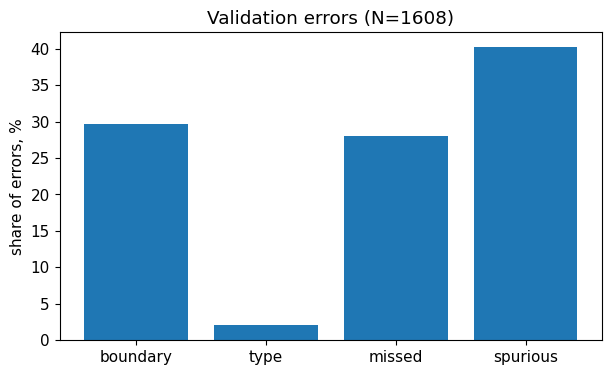


 boundary (5 разных предложений из 478)
{"index": 1756, "tokens": ["Nociceptive", "effects", "induced", "by", "intrathecal", "administration", "of", "prostaglandin", "D2,", "E2,", "or", "F2", "alpha", "to", "conscious", "mice", "."], "gold_span": [7, 13, "Chemical"], "pred_span": [7, 9, "Chemical"], "gold_spans": [[7, 13, "Chemical"]], "pred_spans": [[7, 9, "Chemical"], [9, 10, "Chemical"], [11, 13, "Chemical"]]}
{"index": 618, "tokens": ["Dose", "-", "related", "beneficial", "and", "adverse", "effects", "of", "dietary", "corticosterone", "on", "organophosphorus", "-", "induced", "delayed", "neuropathy", "in", "chickens", "."], "gold_span": [15, 16, "Disease"], "pred_span": [14, 16, "Disease"], "gold_spans": [[9, 10, "Chemical"], [11, 12, "Chemical"], [15, 16, "Disease"]], "pred_spans": [[9, 10, "Chemical"], [11, 12, "Chemical"], [14, 16, "Disease"]]}
{"index": 779, "tokens": ["Effects", "of", "the", "cyclooxygenase", "-", "2", "specific", "inhibitor", "valdecoxib", "versus", "nonster

23447

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

error_examples = {c: [] for c in ERROR_CATEGORIES}
counter = collections.Counter()
error_type_counts = collections.Counter()
for i, (words, gs, ps) in enumerate(zip(val_tokens, val_gold, val_pred)):
    for category, g, p in categorize_errors(bio_to_spans(gs), bio_to_spans(ps)):
        counter[category] += 1
        error_type_counts[(category, (g if g is not None else p)[2])] += 1
        error_examples[category].append(dict(index=i, tokens=words, gold_span=g, pred_span=p,
                                             gold_spans=bio_to_spans(gs), pred_spans=bio_to_spans(ps)))
errors = {c: counter[c] for c in ERROR_CATEGORIES}
error_total = sum(counter[c] for c in ERROR_CATEGORIES if c != 'correct')
error_percentages = {c: (100 * errors[c] / error_total if error_total else 0.)
                     for c in ERROR_CATEGORIES if c != 'correct'}
error_by_type = {
    category: {entity_type: error_type_counts[(category, entity_type)]
               for entity_type in ENTITY_TYPES}
    for category in ERROR_CATEGORIES
}
print('Counts:', errors)
print('Errors by entity type (gold for missed/boundary/type, predicted for spurious):', error_by_type)
print('Shares of errors (%):', {k: round(v, 2) for k, v in error_percentages.items()})
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(error_percentages.keys(), error_percentages.values())
ax.set_ylabel('share of errors, %')
ax.set_title(f'Validation errors (N={error_total})')
plt.savefig(ARTIFACTS / 'error_categories.png', bbox_inches='tight')
plt.show()

error_sample = {}
for category in ERROR_CATEGORIES[1:]:
    candidates = error_examples[category].copy()
    random.Random(SEED + ERROR_CATEGORIES.index(category)).shuffle(candidates)
    picked, selected_sentence_ids = [], set()
    for item in candidates:
        if item['index'] not in selected_sentence_ids:
            picked.append(item)
            selected_sentence_ids.add(item['index'])
        if len(picked) == 5:
            break
    error_sample[category] = picked
    print('\n', category, f'({len(picked)} разных предложений из {errors[category]})')
    for item in picked:
        print(json.dumps(item, ensure_ascii=False))
(ARTIFACTS / 'error_examples.json').write_text(
    json.dumps(error_examples, ensure_ascii=False, indent=2), encoding='utf-8')
(ARTIFACTS / 'error_sample.json').write_text(
    json.dumps(error_sample, ensure_ascii=False, indent=2), encoding='utf-8')


**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** Самая частая категория ошибок — лишние предсказанные сущности (spurious): 647 случаев, или 40,24% ошибок; далее следуют ошибки границ (478) и пропуски (450). Ошибки границ особенно характерны для Disease (399 случаев против 79 у Chemical), а ложные срабатывания могут возникать на медицинских выражениях, похожих на сущности. Пограничные случаи не следует без экспертной перепроверки считать ошибками аннотаторов. Для уменьшения числа ложных сущностей я бы попробовала фильтрацию по уверенности и добавила сложные отрицательные примеры.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'
assert ABLATION in {'freeze', 'all_subwords'}
set_seed(SEED)
model.cpu()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
abl_model = make_model()
abl_tokenized = tokenized if ABLATION == 'freeze' else data.map(
    tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
    fn_kwargs=dict(label_all_subwords=True))
abl_history, abl_seconds = train_ner(abl_model, abl_tokenized['train'], abl_tokenized['validation'],
                                    freeze_encoder=ABLATION == 'freeze', out_dir='runs/ablation')
abl_pred = predict_word_tags(abl_model, val_tokens)
ablation = dict(setting=ABLATION, validation=full_scores(val_gold, abl_pred),
                main_validation=validation_metrics, train_time_sec=abl_seconds,
                trainable_params=sum(p.numel() for p in abl_model.parameters() if p.requires_grad),
                main_trainable_params=sum(p.numel() for p in model.parameters() if p.requires_grad),
                main_train_time_sec=RUN_TIMES['train_main_sec'], seed=SEED)
print('Primary ablation:', ablation)
del abl_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
if ABLATION == 'freeze' and RUN_HEAD_LR_DIAGNOSTIC:
    set_seed(SEED)
    head_model = make_model()
    head_history, head_seconds = train_ner(
        head_model, tokenized['train'], tokenized['validation'],
        freeze_encoder=True, lr=1e-3, out_dir='runs/freeze_head_lr')
    head_pred = predict_word_tags(head_model, val_tokens)
    ablation['head_lr_diagnostic'] = dict(
        lr=1e-3, epochs=EPOCHS, validation=full_scores(val_gold, head_pred),
        train_time_sec=head_seconds,
        trainable_params=sum(p.numel() for p in head_model.parameters() if p.requires_grad),
        caveat='Diagnostic: learning rate also differs; not a controlled freeze-only comparison')
    print('Extra head-only LR diagnostic:', ablation['head_lr_diagnostic'])
    del head_model
    gc.collect()
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.862', 'grad_norm': 'inf', 'learning_rate': '0', 'epoch': '0.003058'}
{'loss': '1.839', 'grad_norm': '8.82', 'learning_rate': '2.333e-05', 'epoch': '0.2477'}
{'eval_loss': '1.733', 'eval_f1': '0.07355', 'eval_runtime': '7.721', 'eval_samples_per_second': '690.3', 'eval_steps_per_second': '21.63', 'epoch': '0.2477'}
{'loss': '1.608', 'grad_norm': '7.639', 'learning_rate': '2.799e-05', 'epoch': '0.4954'}
{'eval_loss': '1.42', 'eval_f1': '0.1102', 'eval_runtime': '7.992', 'eval_samples_per_second': '667', 'eval_steps_per_second': '20.9', 'epoch': '0.4954'}
{'loss': '1.333', 'grad_norm': '6.339', 'learning_rate': '2.524e-05', 'epoch': '0.7431'}
{'eval_loss': '1.166', 'eval_f1': '0.123', 'eval_runtime': '7.933', 'eval_samples_per_second': '671.9', 'eval_steps_per_second': '21.05', 'epoch': '0.7431'}
{'loss': '1.118', 'grad_norm': '6.167', 'learning_rate': '2.248e-05', 'epoch': '0.9908'}
{'eval_loss': '0.9752', 'eval_f1': '0.0803', 'eval_runtime': '7.864', 'eval_samples_per_second

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.862', 'grad_norm': 'inf', 'learning_rate': '0', 'epoch': '0.003058'}
{'loss': '1.097', 'grad_norm': '0.518', 'learning_rate': '0.0007778', 'epoch': '0.2477'}
{'eval_loss': '0.3368', 'eval_f1': '0.09471', 'eval_runtime': '7.471', 'eval_samples_per_second': '713.4', 'eval_steps_per_second': '22.35', 'epoch': '0.2477'}
{'loss': '0.2414', 'grad_norm': '0.3525', 'learning_rate': '0.0009331', 'epoch': '0.4954'}
{'eval_loss': '0.1727', 'eval_f1': '0.6437', 'eval_runtime': '7.668', 'eval_samples_per_second': '695.1', 'eval_steps_per_second': '21.78', 'epoch': '0.4954'}
{'loss': '0.1749', 'grad_norm': '0.1928', 'learning_rate': '0.0008413', 'epoch': '0.7431'}
{'eval_loss': '0.1423', 'eval_f1': '0.6978', 'eval_runtime': '7.843', 'eval_samples_per_second': '679.6', 'eval_steps_per_second': '21.29', 'epoch': '0.7431'}
{'loss': '0.1527', 'grad_norm': '0.2117', 'learning_rate': '0.0007494', 'epoch': '0.9908'}
{'eval_loss': '0.1291', 'eval_f1': '0.7211', 'eval_runtime': '7.822', 'eval_sam

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** Я сравнила полное дообучение (88,76% validation F1, 218,6 с, 107,7 млн обучаемых параметров) с замороженным энкодером при LR = 3e-5 (0,39% F1, 135,3 с, 3845 параметров). Такой низкий результат связан не только с заморозкой: при увеличении LR классификационной головы до 1e-3 F1 достиг 77,55%. Дополнительный эксперимент нельзя считать чистой абляцией заморозки, поскольку одновременно изменялся learning rate. Для более надёжных выводов я бы отдельно подобрала LR головы и повторила обучение на нескольких seed.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** В работе BioBERT достигла 88,14% Entity F1 на test против 62,55% у словарного бейзлайна на validation. Качество для Chemical оказалось выше, чем для Disease (92,95% против 82,55%), а самой частой ошибкой стали лишние спаны (40,24% ошибок). Заморозка энкодера при исходном learning rate почти остановила обучение головы, однако увеличение LR повысило F1 замороженной модели до 77,55% на validation. Добавление 50 новых предложений немного улучшило test F1 — с 88,14% до 88,23%, а обычный BERT уступил BioBERT (85,01% против 88,14%). Фильтрация с порогом 0,86 повысила test F1 до 88,88%. Основными ограничениями остаются ошибки границ заболеваний, чувствительность к регистру и небольшой объём дополнительной разметки; дальше я бы добавила сложные примеры и проверила переносимость на другой корпус.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


METRICS_PAYLOAD = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(METRICS_PAYLOAD), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in METRICS_PAYLOAD.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

METRICS_PAYLOAD.update(dataset_revision=DATASET_REVISION, validation=validation_metrics,
               dataset_stats=dataset_stats, roundtrip=roundtrip_stats, truncation=truncation_stats,
               error_percentages=error_percentages, error_by_type=error_by_type,
               hyperparameters=dict(lr=LR, batch_size=BATCH_SIZE, epochs=EPOCHS,
                                    max_length=MAX_LENGTH, seed=SEED, tokenizer_do_lower_case=tokenizer.do_lower_case),
               versions=dict(torch=torch.__version__, transformers=transformers.__version__,
                             datasets=datasets.__version__), bonus_tasks=sorted(BONUS_TASKS))
(ARTIFACTS / 'training_history.json').write_text(json.dumps(json_ready(history), indent=2), encoding='utf-8')
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(METRICS_PAYLOAD), ensure_ascii=False, indent=2), encoding='utf-8')

def write_metrics():
    required = {'track', 'model', 'revision', 'dataset', 'baseline', 'final',
                'ablation', 'errors', 'device', 'train_time_sec', 'fast_mode'}
    assert required <= set(METRICS_PAYLOAD), required - set(METRICS_PAYLOAD)
    assert METRICS_PAYLOAD['track'] == 'nlp'
    assert abs(METRICS_PAYLOAD['final']['f1_micro'] - final['f1_micro']) < 1e-12
    path = ARTIFACTS / 'metrics.json'
    path.write_text(json.dumps(json_ready(METRICS_PAYLOAD), ensure_ascii=False, indent=2), encoding='utf-8')
    saved = json.loads(path.read_text(encoding='utf-8'))
    assert required <= saved.keys() and saved['final']['f1_micro'] == float(final['f1_micro'])


write_metrics()


def save_bonus(name, result):
    BONUS_RESULTS[name] = result
    (ARTIFACTS / 'bonus_results.json').write_text(
        json.dumps(json_ready(BONUS_RESULTS), ensure_ascii=False, indent=2), encoding='utf-8')
    METRICS_PAYLOAD['bonuses'] = BONUS_RESULTS
    write_metrics()

{"track": "nlp", "model": "dmis-lab/biobert-base-cased-v1.2", "revision": "67c9c25b46986521ca33df05d8540da1210b3256", "dataset": "tner/bc5cdr", "classes": ["Chemical", "Disease"], "n_train": 5228, "n_val": 5330, "n_test": 5865, "params_total": 107723525, "ablation": {"setting": "freeze", "validation": {"f1_micro": 0.003944363711853851, "f1_macro": 0.0035302861389817915, "precision": 0.4418604651162791, "recall": 0.001981023876550933, "token_f1": 0.0036542739116619, "per_type": {"Chemical": {"precision": 0.5428571428571428, "recall": 0.003553394426781373, "f1-score": 0.007060572277963583, "supp
final F1 micro 0.8814


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
def load_manual_annotations(path):
    rows, seen = [], set()
    forbidden = {tuple(ex['tokens']) for split in raw.values() for ex in split}
    for line_no, line in enumerate(Path(path).read_text(encoding='utf-8').splitlines(), 1):
        if not line.strip():
            continue
        obj = json.loads(line)
        assert obj.get('annotated') is True, f'Line {line_no}: annotation is not complete'
        words = obj['tokens']
        assert words and all(isinstance(w, str) and w for w in words)
        assert tuple(words) not in forbidden, f'Line {line_no}: duplicate of original corpus'
        assert tuple(words) not in seen, f'Line {line_no}: duplicate new sentence'
        assert obj.get('source') and obj.get('annotation_notes'), 'Record source and annotation decisions'
        seen.add(tuple(words))
        spans = [tuple(s) for s in obj['spans']]
        assert all(s[2] in ENTITY_TYPES for s in spans)
        tags = spans_to_bio(spans, len(words))
        assert bio_to_spans(tags) == sorted(spans)
        rows.append(dict(tokens=words, ner_tags=[label2id[t] for t in tags]))
    assert len(rows) >= 50, 'Bonus 6.1 needs at least 50 manually annotated new sentences'
    return datasets.Dataset.from_list(rows)


if '6.1' in BONUS_TASKS:
    manual_path = ARTIFACTS / 'manual_annotations.jsonl'
    template_path = ARTIFACTS / 'manual_annotation_template.jsonl'
    if not template_path.exists():
        template = dict(id='new-001', source='URL / citation and reuse terms',
                        tokens=['Replace', 'with', 'a', 'new', 'sentence', '.'],
                        spans=[], annotated=False, annotation_notes='Explain ambiguous boundaries/types')
        template_path.write_text(json.dumps(template, ensure_ascii=False) + '\n', encoding='utf-8')
    if not manual_path.exists():
        save_bonus('6.1', dict(status='awaiting_manual_annotation', required_sentences=50,
                              path=str(manual_path)))
        print('Подготовьте ≥50 НОВЫХ предложений в', manual_path,
              'по шаблону', template_path, 'и повторите эту ячейку. Обучение 6.1 пока пропущено.')
    else:
        extra = load_manual_annotations(manual_path)
        extra_tokens = [list(words) for words in extra['tokens']]
        extra_gold = [[LABEL_NAMES[int(tag)] for tag in tags] for tags in extra['ner_tags']]
        original_on_manual = full_scores(extra_gold, predict_word_tags(model, extra_tokens))
        print('Исходная модель на новых предложениях CDC:',
              {k: round(v, 4) for k, v in original_on_manual.items() if k != 'per_type'})
        extra_tok = extra.map(tokenize_and_align, batched=True, remove_columns=extra.column_names)
        augmented = datasets.concatenate_datasets([tokenized['train'], extra_tok])
        model.cpu()
        set_seed(SEED)
        augmented_model = make_model()
        aug_history, aug_seconds = train_ner(augmented_model, augmented, tokenized['validation'],
                                            out_dir='runs/manual')
        aug_val_pred = predict_word_tags(augmented_model, val_tokens)
        aug_test_pred = predict_word_tags(augmented_model, test_tokens)
        save_bonus('6.1', dict(status='completed', n_new=len(extra), train_time_sec=aug_seconds,
                              original_validation=validation_metrics, original_test=final,
                              original_on_manual=original_on_manual,
                              augmented_validation=full_scores(val_gold, aug_val_pred),
                              augmented_test=full_scores(test_gold, aug_test_pred),
                              policy='new sentences only; original validation/test unchanged; same epochs'))
        print(BONUS_RESULTS['6.1'])
        del augmented_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

Исходная модель на новых предложениях CDC: {'f1_micro': np.float64(0.8235), 'f1_macro': np.float64(0.8483), 'precision': np.float64(0.7975), 'recall': np.float64(0.8514), 'token_f1': 0.838}


Map:   0%|          | 0/50 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.872', 'grad_norm': 'inf', 'learning_rate': '0', 'epoch': '0.00303'}
{'loss': '0.7403', 'grad_norm': '1.422', 'learning_rate': '2.364e-05', 'epoch': '0.2485'}
{'eval_loss': '0.1272', 'eval_f1': '0.7217', 'eval_runtime': '7.682', 'eval_samples_per_second': '693.8', 'eval_steps_per_second': '21.74', 'epoch': '0.2485'}
{'loss': '0.1041', 'grad_norm': '0.9042', 'learning_rate': '2.795e-05', 'epoch': '0.497'}
{'eval_loss': '0.07855', 'eval_f1': '0.8666', 'eval_runtime': '7.912', 'eval_samples_per_second': '673.7', 'eval_steps_per_second': '21.11', 'epoch': '0.497'}
{'loss': '0.08041', 'grad_norm': '1.154', 'learning_rate': '2.519e-05', 'epoch': '0.7455'}
{'eval_loss': '0.08147', 'eval_f1': '0.8742', 'eval_runtime': '7.602', 'eval_samples_per_second': '701.1', 'eval_steps_per_second': '21.97', 'epoch': '0.7455'}
{'loss': '0.072', 'grad_norm': '1.585', 'learning_rate': '2.242e-05', 'epoch': '0.9939'}
{'eval_loss': '0.0731', 'eval_f1': '0.8741', 'eval_runtime': '7.569', 'eval_sample

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** Я разметила 50 новых предложений по восьми страницам CDC о химических веществах и заболеваниях, в том числе четыре предложения без сущностей. Разметка заняла примерно 2 часа, а дополнительное обучение заняло 214 секунд. После включения примеров только в train validation F1 вырос с 88,76% до 88,90%, а test F1 — с 88,14% до 88,23%, то есть эффект оказался небольшим. Больше всего сомнений при разметке у меня вызвали границы и трактовка симптомов, например breathing problems, developmental delays и watery diarrhea.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
def timed_prediction(m, words, tok=None, dev=None):
    dev = dev or device
    m.to(dev).eval()
    predict_word_tags(m, words[:min(8, len(words))], tok=tok, dev=dev, batch_size=BATCH_SIZE)
    if dev.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    pred = predict_word_tags(m, words, tok=tok, dev=dev, batch_size=BATCH_SIZE)
    if dev.type == 'cuda':
        torch.cuda.synchronize()
    return pred, time.perf_counter() - start


if '6.2' in BONUS_TASKS:
    model.cpu()
    comparison_tok = AutoTokenizer.from_pretrained(COMPARISON_MODEL_ID, revision=COMPARISON_REVISION,
                                                   use_fast=True, do_lower_case=False)
    assert comparison_tok.is_fast and comparison_tok.do_lower_case is False
    comparison_data = data.map(tokenize_and_align, batched=True,
                               remove_columns=data['train'].column_names,
                               fn_kwargs=dict(tok=comparison_tok))
    set_seed(SEED)
    comparison_model = make_model(COMPARISON_MODEL_ID, COMPARISON_REVISION)
    cmp_history, cmp_seconds = train_ner(comparison_model, comparison_data['train'],
                                        comparison_data['validation'], tok=comparison_tok,
                                        out_dir='runs/bert_comparison')
    cmp_val = predict_word_tags(comparison_model, val_tokens, tok=comparison_tok)
    cmp_test, cmp_infer = timed_prediction(comparison_model, test_tokens, tok=comparison_tok)
    cmp_params = sum(p.numel() for p in comparison_model.parameters())
    cmp_weight_bytes = sum(p.numel() * p.element_size() for p in comparison_model.parameters())
    comparison_model.cpu()
    _, main_infer = timed_prediction(model, test_tokens)
    model.cpu()
    save_bonus('6.2', dict(model=COMPARISON_MODEL_ID, revision=COMPARISON_REVISION,
                          validation=full_scores(val_gold, cmp_val), test=full_scores(test_gold, cmp_test),
                          train_sec=cmp_seconds, inference_sec=cmp_infer, params=cmp_params,
                          parameter_bytes=cmp_weight_bytes,
                          main_validation=validation_metrics, main_test=final,
                          main_train_sec=RUN_TIMES['train_main_sec'], main_inference_sec=main_infer,
                          main_params=sum(p.numel() for p in model.parameters()),
                          main_parameter_bytes=sum(p.numel() * p.element_size() for p in model.parameters()),
                          device=DEVICE_NAME, inference_batch_size=BATCH_SIZE,
                          tokenizer_cased_both=True, seed=SEED, epochs=EPOCHS, lr=LR,
                          batch_size=BATCH_SIZE))
    print(BONUS_RESULTS['6.2'])
    del comparison_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

Map:   0%|          | 0/5228 [00:00<?, ? examples/s]

Map:   0%|          | 0/5330 [00:00<?, ? examples/s]

Map:   0%|          | 0/5865 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.916', 'grad_norm': 'inf', 'learning_rate': '0', 'epoch': '0.003058'}
{'loss': '0.7919', 'grad_norm': '1.779', 'learning_rate': '2.333e-05', 'epoch': '0.2477'}
{'eval_loss': '0.1733', 'eval_f1': '0.6446', 'eval_runtime': '7.582', 'eval_samples_per_second': '703', 'eval_steps_per_second': '22.02', 'epoch': '0.2477'}
{'loss': '0.13', 'grad_norm': '1.277', 'learning_rate': '2.799e-05', 'epoch': '0.4954'}
{'eval_loss': '0.1136', 'eval_f1': '0.8057', 'eval_runtime': '7.945', 'eval_samples_per_second': '670.9', 'eval_steps_per_second': '21.02', 'epoch': '0.4954'}
{'loss': '0.1042', 'grad_norm': '2.518', 'learning_rate': '2.524e-05', 'epoch': '0.7431'}
{'eval_loss': '0.103', 'eval_f1': '0.8313', 'eval_runtime': '7.782', 'eval_samples_per_second': '684.9', 'eval_steps_per_second': '21.46', 'epoch': '0.7431'}
{'loss': '0.08549', 'grad_norm': '1.227', 'learning_rate': '2.248e-05', 'epoch': '0.9908'}
{'eval_loss': '0.08641', 'eval_f1': '0.8475', 'eval_runtime': '7.486', 'eval_samples_p

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** Я сравнила BioBERT с google-bert/bert-base-cased при одинаковых настройках обучения: три эпохи, LR = 3e-5, batch size = 16, одинаковые seed и сплиты. У обеих моделей около 107,7 млн параметров и размер весов примерно 431 МБ; на test BioBERT получила F1 = 88,14% против 85,01% у обычного BERT. Время обучения составило 218,6 с и 213,0 с, а инференса — 8,50 с и 9,24 с соответственно, поэтому доменная модель повысила качество без заметного роста вычислительных затрат.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

Number of validation sentences with changed token IDs: {'lowercase': 4569, 'uppercase': 5072, 'typos_20pct': 4011}
{
  "original": {
    "f1_micro": 0.8876317819490872,
    "f1_macro": 0.8821298185701256,
    "precision": 0.8757864826466409,
    "recall": 0.8998018976123449,
    "delta_f1": 0.0
  },
  "lowercase": {
    "f1_micro": 0.8539841914120914,
    "f1_macro": 0.8497912020022561,
    "precision": 0.8753969122960692,
    "recall": 0.8335939943697216,
    "delta_f1": -0.03364759053699584
  },
  "uppercase": {
    "f1_micro": 0.12113697062190004,
    "f1_macro": 0.10422284194741517,
    "precision": 0.7110862262038073,
    "recall": 0.0662079032426233,
    "delta_f1": -0.7664948113271872
  },
  "typos_20pct": {
    "f1_micro": 0.8482949876746096,
    "f1_macro": 0.8416642394451832,
    "precision": 0.8358465742333772,
    "recall": 0.861119799812324,
    "delta_f1": -0.03933679427447756
  }
}


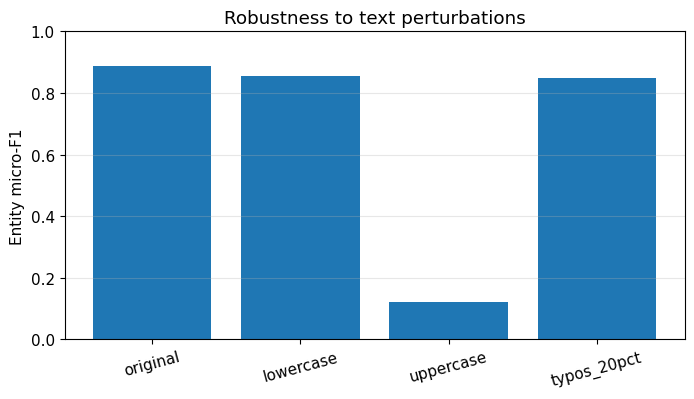

In [32]:
if '6.3' in BONUS_TASKS:
    import random
    import string

    rng = random.Random(SEED)

    def add_typos(sentences, probability=0.2):
        result = []
        for words in sentences:
            changed = []
            for word in words:
                if len(word) >= 4 and word.isalpha() and rng.random() < probability:
                    pos = rng.randrange(len(word))
                    letters = string.ascii_uppercase if word[pos].isupper() else string.ascii_lowercase
                    replacement = rng.choice([c for c in letters if c != word[pos]])
                    word = word[:pos] + replacement + word[pos + 1:]
                changed.append(word)
            result.append(changed)
        return result

    variants = {
        "original": val_tokens,
        "lowercase": [[w.lower() for w in sent] for sent in val_tokens],
        "uppercase": [[w.upper() for w in sent] for sent in val_tokens],
        "typos_20pct": add_typos(val_tokens)
    }

    results = {}

    for name, tokens in variants.items():
        pred = val_pred if name == "original" else predict_word_tags(model, tokens)
        shift_scores = full_scores(val_gold, pred)

        results[name] = {
            "f1_micro": shift_scores["f1_micro"],
            "f1_macro": shift_scores["f1_macro"],
            "precision": shift_scores["precision"],
            "recall": shift_scores["recall"],
            "delta_f1": shift_scores["f1_micro"] - validation_metrics["f1_micro"]
        }

    def count_changed_tokenization(original, mutated):
        changes = 0
        for original_words, changed_words in zip(original, mutated):
            first = tokenizer(original_words, is_split_into_words=True,
                              truncation=True, max_length=MAX_LENGTH)['input_ids']
            second = tokenizer(changed_words, is_split_into_words=True,
                               truncation=True, max_length=MAX_LENGTH)['input_ids']
            changes += first != second
        return changes

    changed_inputs = {name: count_changed_tokenization(val_tokens, tokens)
                      for name, tokens in variants.items() if name != 'original'}
    print('Number of validation sentences with changed token IDs:', changed_inputs)
    assert tokenizer.do_lower_case is False, 'The BioBERT tokenizer must preserve case'
    save_bonus('6.3', dict(scores=results, tokenizer_changed_sentences=changed_inputs,
                           tokenizer_do_lower_case=tokenizer.do_lower_case,
                           seed=SEED, typo_probability=0.2))

    print(json.dumps(json_ready(results), ensure_ascii=False, indent=2))

    plt.figure(figsize=(8, 4))
    plt.bar(results.keys(), [r["f1_micro"] for r in results.values()])
    plt.ylabel("Entity micro-F1")
    plt.title("Robustness to text perturbations")
    plt.ylim(0, 1)
    plt.xticks(rotation=15)
    plt.grid(axis="y", alpha=0.3)
    plt.savefig(ARTIFACTS / "robustness_shift.png", bbox_inches="tight")
    plt.show()


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** По сравнению с исходным F1 = 88,76% перевод в lowercase снизил показатель до 85,40%, опечатки с вероятностью 20% — до 84,83%, а uppercase — до 12,11%. Наиболее сильное падение при uppercase согласуется с использованием регистрозависимого токенизатора BioBERT (do_lower_case = False): меняются сабворды и привычные для модели признаки.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    import io
    import warnings
    cpu = torch.device('cpu')
    model.cpu().eval()
    engines = torch.backends.quantized.supported_engines
    engine = next((e for e in ['x86', 'fbgemm', 'qnnpack'] if e in engines), None)
    if engine is None:
        raise RuntimeError(f'No quantized CPU backend: {engines}')
    torch.backends.quantized.engine = engine
    fp32_model = copy.deepcopy(model).cpu().float().eval()
    if hasattr(fp32_model, 'set_attn_implementation'):
        fp32_model.set_attn_implementation('eager')
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', DeprecationWarning)
        int8_model = torch.ao.quantization.quantize_dynamic(
            fp32_model, {torch.nn.Linear}, dtype=torch.qint8, inplace=False).eval()
    bench_words = val_tokens[:min(32, len(val_tokens))]
    bench_enc = tokenizer(bench_words, is_split_into_words=True, padding=True,
                          truncation=True, max_length=MAX_LENGTH, return_tensors='pt')
    def benchmark_cpu(m, repeats=12):
        with torch.inference_mode():
            for _ in range(3):
                m(**bench_enc)
            durations = []
            for _ in range(repeats):
                start = time.perf_counter()
                m(**bench_enc)
                durations.append(time.perf_counter() - start)
        return dict(median_ms=1000 * float(np.median(durations)),
                    mean_ms=1000 * float(np.mean(durations)), repeats=repeats)
    def serialized_size(m):
        buf = io.BytesIO()
        torch.save(m.state_dict(), buf)
        return buf.tell()
    fp32_bench, int8_bench = benchmark_cpu(fp32_model), benchmark_cpu(int8_model)
    fp32_pred = predict_word_tags(fp32_model, val_tokens, dev=cpu, batch_size=BATCH_SIZE)
    int8_pred = predict_word_tags(int8_model, val_tokens, dev=cpu, batch_size=BATCH_SIZE)
    fp32_scores, int8_scores = full_scores(val_gold, fp32_pred), full_scores(val_gold, int8_pred)
    delta = int8_scores['f1_micro'] - fp32_scores['f1_micro']
    save_bonus('6.4', dict(method='dynamic_int8_linear', device='cpu', backend=engine,
                          torch_threads=torch.get_num_threads(), batch_shape=list(bench_enc['input_ids'].shape),
                          timing_scope='pretokenized forward; 3 warmups + 12 timed repeats',
                          fp32=fp32_bench, int8=int8_bench,
                          speedup=fp32_bench['median_ms'] / int8_bench['median_ms'],
                          fp32_bytes=serialized_size(fp32_model), int8_bytes=serialized_size(int8_model),
                          fp32_validation=fp32_scores, int8_validation=int8_scores,
                          f1_delta=delta, f1_tolerance=0.005, within_tolerance=bool(delta >= -0.005)))
    print(BONUS_RESULTS['6.4'])
    if delta < -0.005:
        print('Потеря F1 > 0.005: ускорение не принимаем без обсуждения/другого метода.')
    del fp32_model, int8_model
    gc.collect()

/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  qweight = torch.quantize_per_tensor(


{'method': 'dynamic_int8_linear', 'device': 'cpu', 'backend': 'x86', 'torch_threads': 1, 'batch_shape': [32, 54], 'timing_scope': 'pretokenized forward; 3 warmups + 12 timed repeats', 'fp32': {'median_ms': 2607.52199749993, 'mean_ms': 2783.334925583309, 'repeats': 12}, 'int8': {'median_ms': 2188.5507575000247, 'mean_ms': 2330.3617264166405, 'repeats': 12}, 'speedup': 1.191437753300497, 'fp32_bytes': 430972017, 'int8_bytes': 176213709, 'fp32_validation': {'f1_micro': np.float64(0.8876889848812095), 'f1_macro': np.float64(0.8821968501440624), 'precision': np.float64(0.8757990867579909), 'recall': np.float64(0.8999061620269002), 'token_f1': 0.8838636095489047, 'per_type': {'Chemical': {'precision': np.float64(0.9364723467862481), 'recall': np.float64(0.9373480456330653), 'f1-score': np.float64(0.9369099915879989), 'support': np.int64(5347)}, 'Disease': {'precision': np.float64(0.8036864312680435), 'recall': np.float64(0.8527332704995287), 'f1-score': np.float64(0.8274837087001258), 'suppo

**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** Я применила динамическую INT8-квантизацию линейных слоёв и измерила время на CPU (x86, один поток) для заранее токенизированного батча из 32 предложений после прогрева и 12 повторов. Медианная задержка снизилась с 2607,5 до 2188,6 мс (ускорение 1,19×), а размер сериализованного state_dict — примерно с 431 до 176 МБ. Validation F1 изменился с 88,77% до 88,29% (−0,47 п.п.), что укладывается в допустимое снижение 0,5 п.п. Ускорение ограничено тем, что часть операций, включая некоторые вычисления attention, осталась неквантизованной.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

Selected on validation: {'threshold': 0.86, 'f1_micro': np.float64(0.8968253968253967), 'f1_macro': np.float64(0.8908864368472531), 'precision': np.float64(0.9232637738765596), 'recall': np.float64(0.8718590345115212)} 
Test: {'f1_micro': np.float64(0.8887730636922756), 'f1_macro': np.float64(0.884271357503166), 'precision': np.float64(0.9092460275141303), 'recall': np.float64(0.8692017534916913), 'token_f1': 0.878814935064935, 'per_type': {'Chemical': {'precision': np.float64(0.9489065221598606), 'recall': np.float64(0.9104921077065924), 'f1-score': np.float64(0.9293025018953753), 'support': np.int64(5385)}, 'Disease': {'precision': np.float64(0.8605700712589074), 'recall': np.float64(0.8189421338155516), 'f1-score': np.float64(0.8392402131109566), 'support': np.int64(4424)}}}


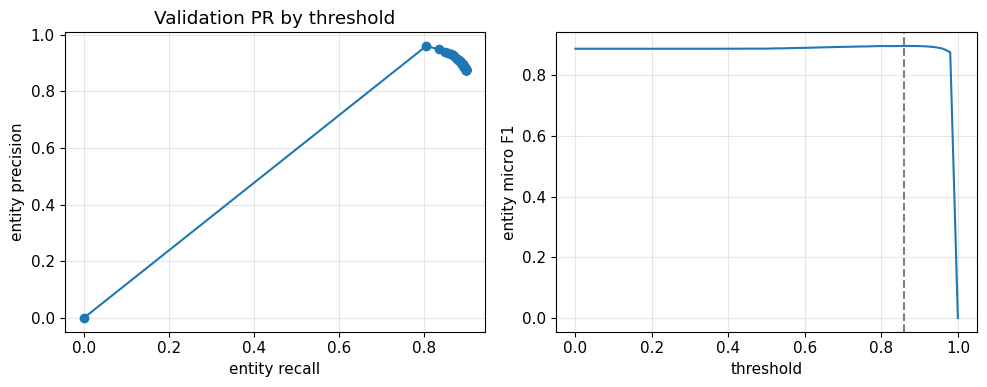

In [34]:
def threshold_spans(tags, probabilities, threshold):
    spans = bio_to_spans(tags)
    kept = [s for s in spans if float(np.mean(probabilities[s[0]:s[1]])) >= threshold]
    return spans_to_bio(kept, len(tags))


if '6.5' in BONUS_TASKS:
    threshold_pred, threshold_probs = predict_word_tags(model, val_tokens, return_probs=True)
    thresholds = np.linspace(0., 1., 51)
    sweep = []
    for threshold in thresholds:
        pred = [threshold_spans(ts, ps, threshold) for ts, ps in zip(threshold_pred, threshold_probs)]
        sweep.append(dict(threshold=float(threshold), **entity_scores(val_gold, pred)))
    best = max(sweep, key=lambda r: (r['f1_micro'], -r['threshold']))
    assert sweep[0]['f1_micro'] == entity_scores(val_gold, threshold_pred)['f1_micro']
    test_raw, test_probs = predict_word_tags(model, test_tokens, return_probs=True)
    test_filtered = [threshold_spans(ts, ps, best['threshold']) for ts, ps in zip(test_raw, test_probs)]
    save_bonus('6.5', dict(confidence='mean predicted-tag probability over span words',
                          selection_split='validation', best=best, threshold_zero=sweep[0],
                          test=full_scores(test_gold, test_filtered), test_threshold_zero=final, sweep=sweep))
    print('Selected on validation:', best, '\nTest:', BONUS_RESULTS['6.5']['test'])
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot([r['recall'] for r in sweep], [r['precision'] for r in sweep], 'o-')
    axes[0].set(xlabel='entity recall', ylabel='entity precision', title='Validation PR by threshold')
    axes[1].plot(thresholds, [r['f1_micro'] for r in sweep])
    axes[1].axvline(best['threshold'], linestyle='--', color='gray')
    axes[1].set(xlabel='threshold', ylabel='entity micro F1')
    for ax in axes:
        ax.grid(alpha=.3)
    plt.tight_layout()
    plt.savefig(ARTIFACTS / 'threshold_pr.png')
    plt.show()

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** В качестве уверенности я использовала среднюю вероятность предсказанных тегов по словам спана и выбрала на validation порог 0,86. Validation F1 вырос с 88,76% до 89,68%, а test F1 — с 88,14% до 88,88%, при этом test recall снизился с 90,23% до 86,92%. Средняя уверенность сглаживает слабые значения отдельных слов, тогда как минимум делает оценку зависимой от самого неуверенного слова. Порог удаляет сомнительные кандидаты, но не может восстановить пропущенные сущности.

In [35]:
required_metrics = {'track', 'model', 'revision', 'dataset', 'baseline', 'final',
                    'ablation', 'errors', 'device', 'train_time_sec', 'fast_mode'}
metrics_on_disk = json.loads((ARTIFACTS / 'metrics.json').read_text(encoding='utf-8'))
bonus_on_disk = json.loads((ARTIFACTS / 'bonus_results.json').read_text(encoding='utf-8')) if BONUS_TASKS else {}
assert required_metrics <= metrics_on_disk.keys(), required_metrics - metrics_on_disk.keys()
assert metrics_on_disk['hyperparameters']['tokenizer_do_lower_case'] is False
assert abs(metrics_on_disk['final']['f1_micro'] - final['f1_micro']) < 1e-12
assert BONUS_TASKS <= bonus_on_disk.keys(), f'Missing bonuses: {BONUS_TASKS - bonus_on_disk.keys()}'
assert '6.1' not in BONUS_TASKS or bonus_on_disk['6.1']['status'] == 'completed'
assert set(metrics_on_disk.get('bonuses', {})) == set(bonus_on_disk)
print('PASS: metrics.json schema, test F1, cased tokenizer, bonus_results.json')
print('test F1:', round(metrics_on_disk['final']['f1_micro'], 4), 'bonus ids:', sorted(bonus_on_disk))


PASS: metrics.json schema, test F1, cased tokenizer, bonus_results.json
test F1: 0.8814 bonus ids: ['6.1', '6.2', '6.3', '6.4', '6.5']
